In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('energydata_complete.csv')

In [5]:
df.shape

(19735, 29)

In [7]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


In [9]:
df.columns

Index(['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3',
       'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8',
       'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed',
       'Visibility', 'Tdewpoint', 'rv1', 'rv2'],
      dtype='object')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9  

In [13]:
df.isnull().sum()

date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64

In [15]:
df.duplicated().sum()

0

In [17]:
df['date'] = pd.to_datetime(df['date'])

In [19]:
df['date'].dtype

dtype('<M8[ns]')

In [21]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['hour'] = df['date'].dt.hour
df['minute'] = df['date'].dt.minute
df['day_of_week'] = df['date'].dt.dayofweek

In [23]:
df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,Visibility,Tdewpoint,rv1,rv2,year,month,day,hour,minute,day_of_week
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,63.000000,5.3,13.275433,13.275433,2016,1,11,17,0,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,59.166667,5.2,18.606195,18.606195,2016,1,11,17,10,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,55.333333,5.1,28.642668,28.642668,2016,1,11,17,20,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,51.500000,5.0,45.410389,45.410389,2016,1,11,17,30,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,47.666667,4.9,10.084097,10.084097,2016,1,11,17,40,0


In [25]:
df['is_weekend'] = df['day_of_week'].apply(
    lambda x: 1 if x >= 5 else 0
)

In [27]:
df['Appliances'].describe()

count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

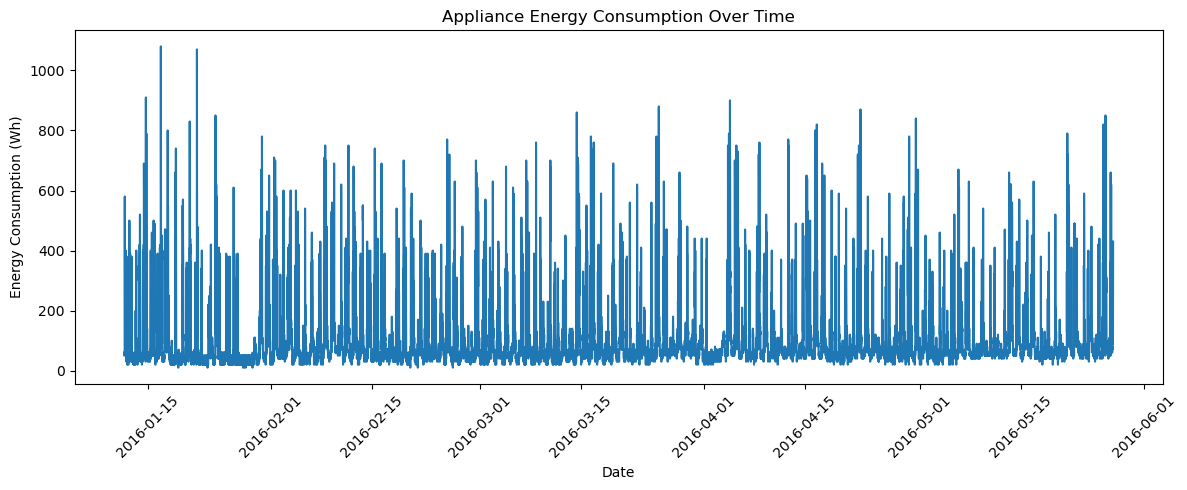

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(df['date'], df['Appliances'])

plt.title('Appliance Energy Consumption Over Time')
plt.xlabel('Date')
plt.ylabel('Energy Consumption (Wh)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

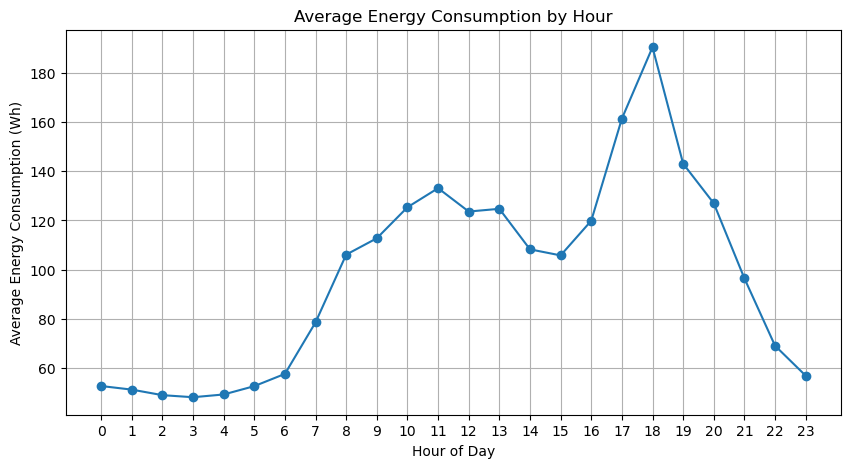

In [31]:
hourly_consumption = df.groupby('hour')['Appliances'].mean()

plt.figure(figsize=(10, 5))

plt.plot(hourly_consumption.index, hourly_consumption.values, marker='o')

plt.title('Average Energy Consumption by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (Wh)')

plt.xticks(range(24))

plt.grid(True)

plt.show()

In [33]:
weekend_consumption = df.groupby('is_weekend')['Appliances'].mean()

print(weekend_consumption)

is_weekend
0     96.587674
1    100.581140
Name: Appliances, dtype: float64


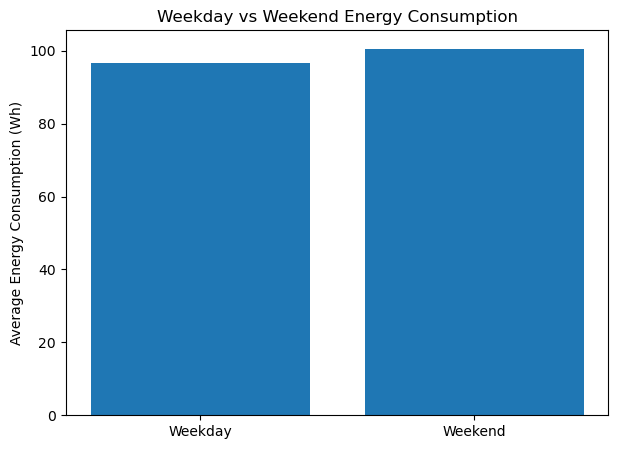

In [35]:
plt.figure(figsize=(7, 5))

plt.bar(
    ['Weekday', 'Weekend'],
    weekend_consumption.values
)

plt.title('Weekday vs Weekend Energy Consumption')
plt.ylabel('Average Energy Consumption (Wh)')

plt.show()

In [37]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation['Appliances'].sort_values(ascending=False)

Appliances     1.000000
hour           0.216792
lights         0.197278
T2             0.120073
T6             0.117638
T_out          0.099155
Windspeed      0.087122
RH_1           0.086031
T3             0.085060
T1             0.055447
T4             0.040281
T8             0.039572
RH_3           0.036292
T7             0.025801
T5             0.019760
is_weekend     0.017437
RH_4           0.016965
Tdewpoint      0.015353
minute         0.013216
T9             0.010010
RH_5           0.006955
day_of_week    0.003060
day            0.002366
Visibility     0.000230
rv1           -0.011145
rv2           -0.011145
month         -0.011606
Press_mm_hg   -0.034885
RH_9          -0.051462
RH_7          -0.055642
RH_2          -0.060465
RH_6          -0.083178
RH_8          -0.094039
RH_out        -0.152282
year                NaN
Name: Appliances, dtype: float64

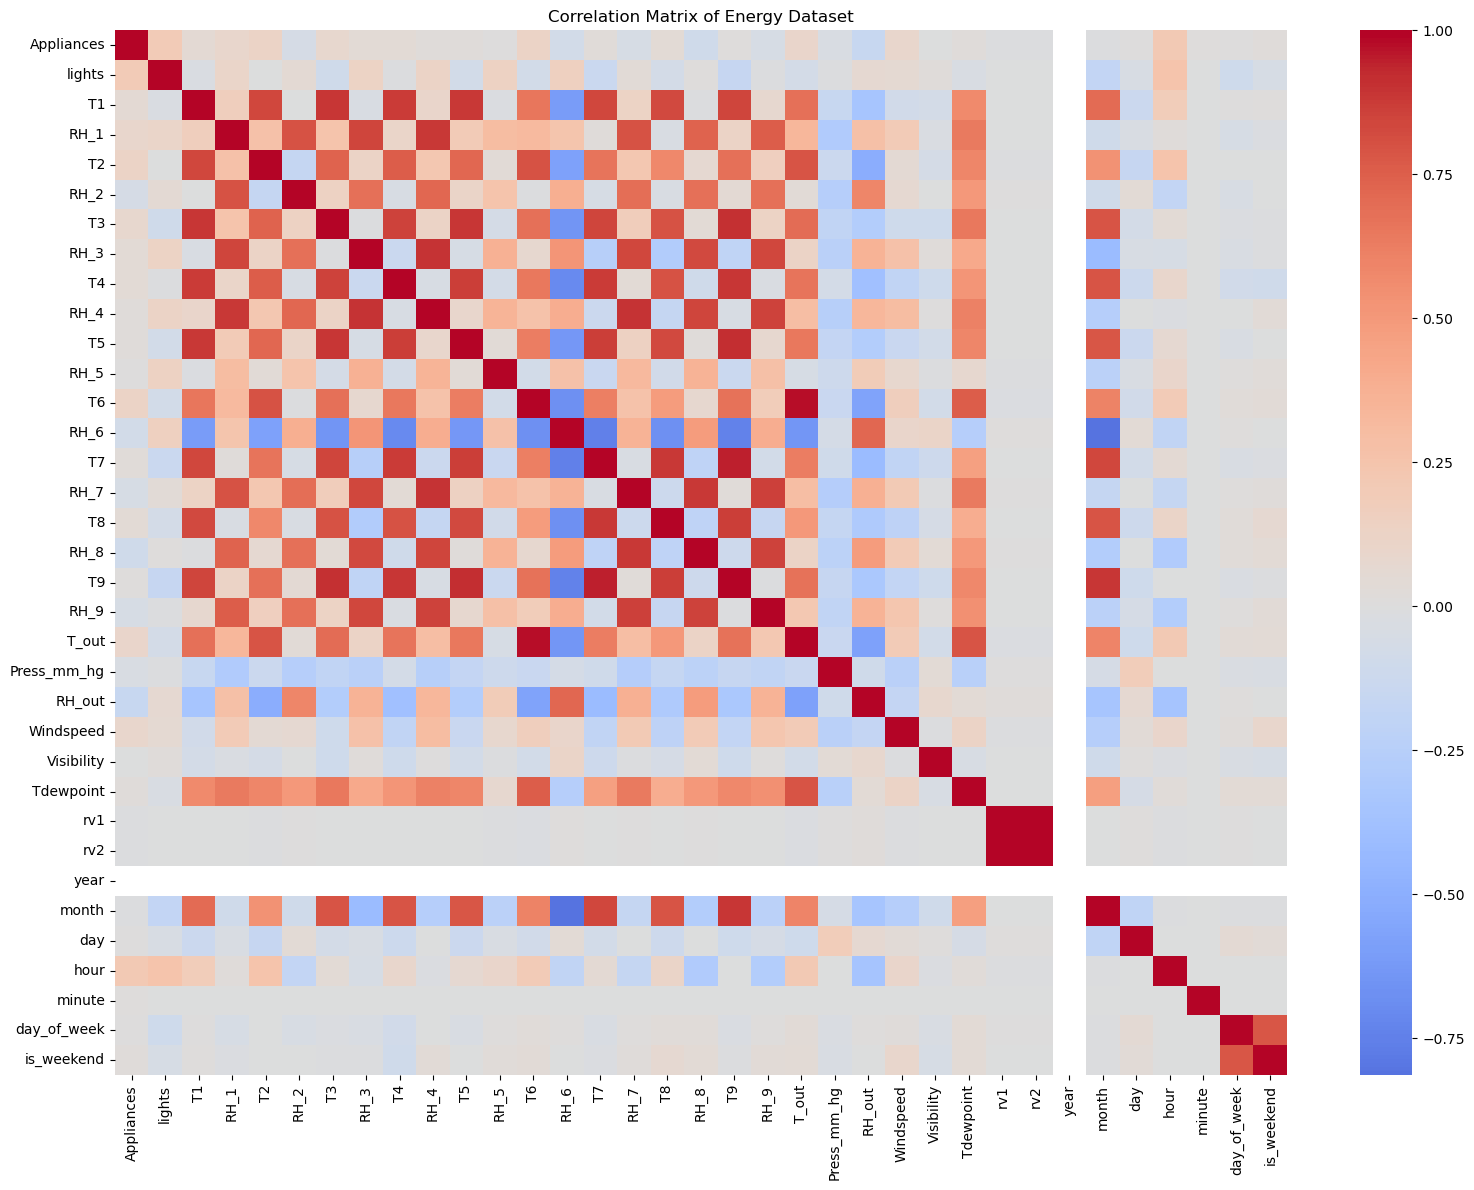

In [39]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix of Energy Dataset')

plt.tight_layout()

plt.show()

In [41]:
target = 'Appliances'

In [43]:
features = [
    'lights',
    'T1',
    'RH_1',
    'T2',
    'RH_2',
    'T3',
    'RH_3',
    'T4',
    'RH_4',
    'T5',
    'RH_5',
    'T6',
    'RH_6',
    'T7',
    'RH_7',
    'T8',
    'RH_8',
    'T9',
    'RH_9',
    'T_out',
    'Press_mm_hg',
    'RH_out',
    'Windspeed',
    'Visibility',
    'Tdewpoint',
    'rv1',
    'rv2',
    'hour',
    'day_of_week',
    'is_weekend'
]

In [45]:
X = df[features]
y = df[target]

In [47]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (19735, 30)
y shape: (19735,)


In [49]:
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [51]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 15788
Testing samples: 3947


In [53]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np

In [54]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [57]:
rf_predictions = rf_model.predict(X_test)

In [59]:
print(rf_predictions[:10])

[179.9 157.2 171.5 106.4 164.8 164.2 153.1 131.7 132.2 131.7]


In [61]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("---------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2  :", rf_r2)

Random Forest Results
---------------------
MAE : 171.800532049658
RMSE: 211.88622325739647
R2  : -4.416951747137445


In [63]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

GradientBoostingRegressor(learning_rate=0.05, random_state=42)

In [64]:
gb_predictions = gb_model.predict(X_test)

In [65]:
gb_mae = mean_absolute_error(y_test, gb_predictions)

gb_rmse = np.sqrt(
    mean_squared_error(y_test, gb_predictions)
)

gb_r2 = r2_score(y_test, gb_predictions)

print("Gradient Boosting Results")
print("-------------------------")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R2  :", gb_r2)

Gradient Boosting Results
-------------------------
MAE : 122.8106210616828
RMSE: 158.5571002380103
R2  : -2.033338772137056


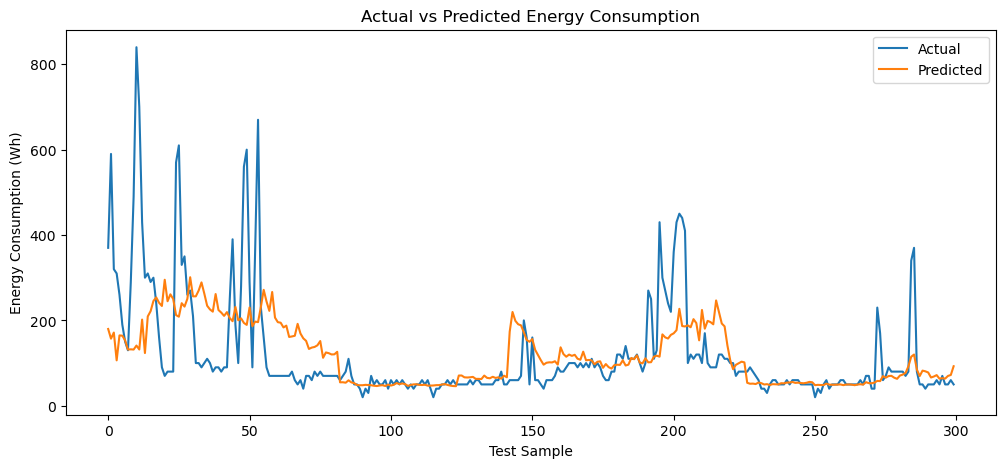

In [66]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.values[:300],
    label='Actual'
)

plt.plot(
    rf_predictions[:300],
    label='Predicted'
)

plt.title('Actual vs Predicted Energy Consumption')

plt.xlabel('Test Sample')
plt.ylabel('Energy Consumption (Wh)')

plt.legend()

plt.show()

In [71]:
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
27,hour,0.157061
5,T3,0.064301
6,RH_3,0.045806
20,Press_mm_hg,0.043286
10,RH_5,0.042582
15,T8,0.040499
4,RH_2,0.040039
24,Tdewpoint,0.033322
0,lights,0.031748
8,RH_4,0.030835


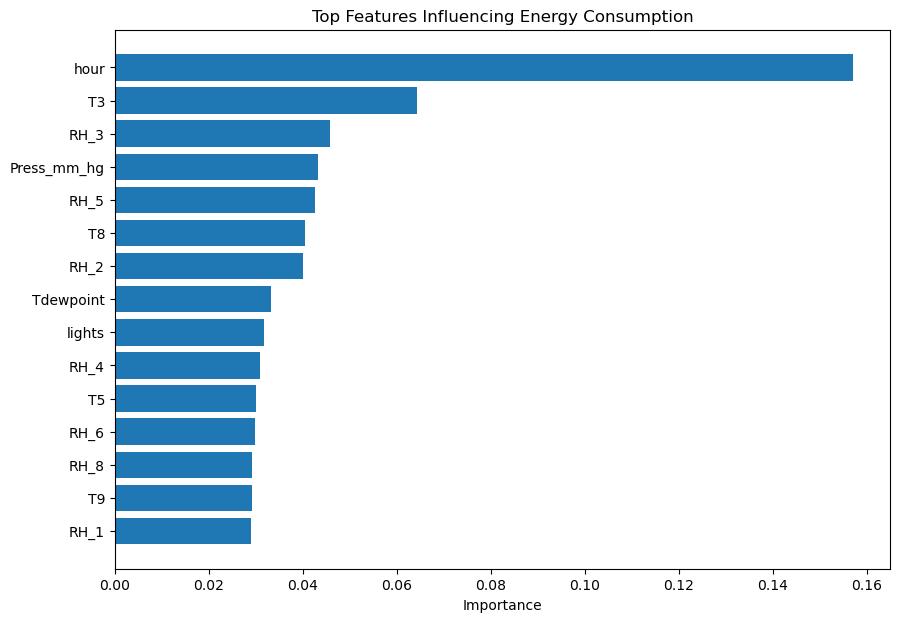

In [73]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15)

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.gca().invert_yaxis()

plt.title('Top Features Influencing Energy Consumption')
plt.xlabel('Importance')

plt.show()

In [75]:
import os
import joblib

os.makedirs('../models', exist_ok=True)

joblib.dump(
    rf_model,
    '../models/energy_prediction_model.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [77]:
import os

print(os.path.exists('../models/energy_prediction_model.pkl'))

True


In [79]:
import os
import joblib

os.makedirs('../models', exist_ok=True)

joblib.dump(
    features,
    '../models/features.pkl'
)

print("features.pkl created successfully!")

features.pkl created successfully!


In [81]:
from sklearn.ensemble import IsolationForest
import pandas as pd
import numpy as np
import joblib

In [83]:
anomaly_features = [
    'Appliances',
    'lights',
    'T_out',
    'RH_out',
    'Windspeed',
    'Visibility',
    'hour',
    'day_of_week',
    'is_weekend'
]

anomaly_data = df[anomaly_features].copy()

anomaly_data.head()

,Appliances,lights,T_out,RH_out,Windspeed,Visibility,hour,day_of_week,is_weekend
0,60,30,6.600000,92.0,7.000000,63.000000,17,0,0
1,60,30,6.483333,92.0,6.666667,59.166667,17,0,0
2,50,30,6.366667,92.0,6.333333,55.333333,17,0,0
3,50,40,6.250000,92.0,6.000000,51.500000,17,0,0
4,60,40,6.133333,92.0,5.666667,47.666667,17,0,0


In [85]:
anomaly_data.isnull().sum()

Appliances     0
lights         0
T_out          0
RH_out         0
Windspeed      0
Visibility     0
hour           0
day_of_week    0
is_weekend     0
dtype: int64

In [87]:
anomaly_data.shape

(19735, 9)

In [89]:
anomaly_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

anomaly_model.fit(anomaly_data)

IsolationForest(contamination=0.05, n_estimators=200, n_jobs=-1,
                random_state=42)

In [91]:
anomaly_predictions = anomaly_model.predict(anomaly_data)

In [93]:
anomaly_data['anomaly'] = anomaly_predictions

anomaly_data['anomaly_label'] = anomaly_data['anomaly'].map({
    1: 'Normal',
    -1: 'Anomaly'
})

In [95]:
anomaly_data[['Appliances', 'anomaly_label']].head(20)

,Appliances,anomaly_label
0,60,Anomaly
1,60,Normal
2,50,Normal
3,50,Anomaly
4,60,Anomaly
5,50,Normal
6,60,Normal
7,60,Normal
8,60,Normal
9,70,Normal


In [97]:
print(
    anomaly_data['anomaly_label'].value_counts()
)

anomaly_label
Normal     18748
Anomaly      987
Name: count, dtype: int64


In [99]:
total_records = len(anomaly_data)

total_anomalies = (
    anomaly_data['anomaly_label'] == 'Anomaly'
).sum()

anomaly_percentage = (
    total_anomalies / total_records
) * 100

print("Total records:", total_records)
print("Total anomalies:", total_anomalies)
print("Anomaly percentage:", anomaly_percentage)

Total records: 19735
Total anomalies: 987
Anomaly percentage: 5.001266784899924


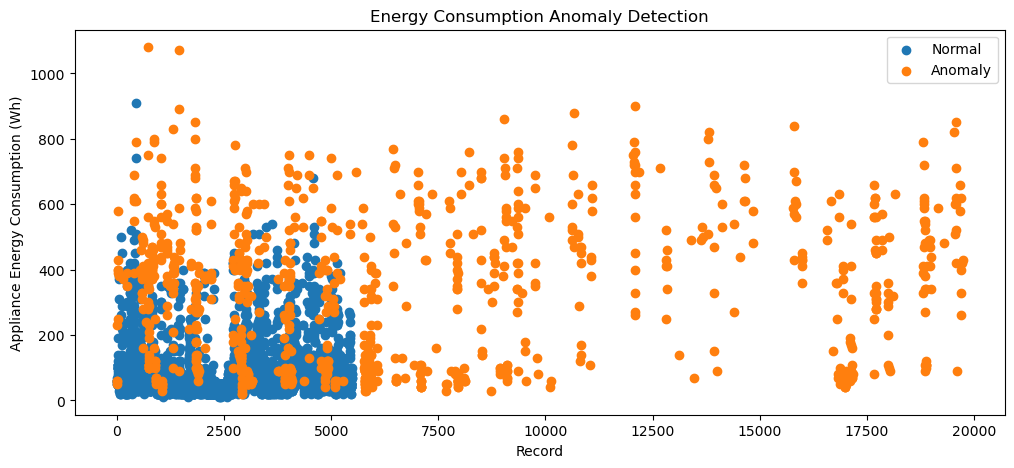

In [101]:
plt.figure(figsize=(12, 5))

normal_data = anomaly_data[
    anomaly_data['anomaly_label'] == 'Normal'
]

abnormal_data = anomaly_data[
    anomaly_data['anomaly_label'] == 'Anomaly'
]

plt.scatter(
    normal_data.index[:5000],
    normal_data['Appliances'].iloc[:5000],
    label='Normal'
)

plt.scatter(
    abnormal_data.index,
    abnormal_data['Appliances'],
    label='Anomaly'
)

plt.title('Energy Consumption Anomaly Detection')
plt.xlabel('Record')
plt.ylabel('Appliance Energy Consumption (Wh)')
plt.legend()

plt.show()

In [103]:
mean_energy = df['Appliances'].mean()
std_energy = df['Appliances'].std()

print("Mean energy:", mean_energy)
print("Standard deviation:", std_energy)

Mean energy: 97.6949581960983
Standard deviation: 102.52489053740692


In [105]:
def calculate_severity(energy):

    if energy > mean_energy + 3 * std_energy:
        return "HIGH"

    elif energy > mean_energy + 2 * std_energy:
        return "MEDIUM"

    else:
        return "LOW"

In [107]:
anomaly_data['severity'] = anomaly_data['Appliances'].apply(
    calculate_severity
)

In [109]:
anomaly_data[
    anomaly_data['anomaly_label'] == 'Anomaly'
][
    ['Appliances', 'severity']
].head(20)

,Appliances,severity
0,60,LOW
3,50,LOW
4,60,LOW
10,230,LOW
11,580,HIGH
12,430,HIGH
13,250,LOW
31,400,MEDIUM
32,400,MEDIUM
33,390,MEDIUM


In [111]:
def create_description(row):

    if row['severity'] == 'HIGH':
        return "Energy consumption is significantly higher than the normal pattern."

    elif row['severity'] == 'MEDIUM':
        return "Energy consumption is higher than the normal pattern."

    else:
        return "Slightly unusual energy consumption detected."

In [113]:
anomaly_data['description'] = anomaly_data.apply(
    create_description,
    axis=1
)

In [115]:
anomaly_data[
    anomaly_data['anomaly_label'] == 'Anomaly'
][
    ['Appliances', 'severity', 'description']
].head(10)

,Appliances,severity,description
0,60,LOW,Slightly unusual energy consumption detected.
3,50,LOW,Slightly unusual energy consumption detected.
4,60,LOW,Slightly unusual energy consumption detected.
10,230,LOW,Slightly unusual energy consumption detected.
11,580,HIGH,Energy consumption is significantly higher tha...
12,430,HIGH,Energy consumption is significantly higher tha...
13,250,LOW,Slightly unusual energy consumption detected.
31,400,MEDIUM,Energy consumption is higher than the normal p...
32,400,MEDIUM,Energy consumption is higher than the normal p...
33,390,MEDIUM,Energy consumption is higher than the normal p...


In [117]:
joblib.dump(
    anomaly_model,
    '../models/anomaly_model.pkl'
)

print("Anomaly model saved successfully!")

Anomaly model saved successfully!


In [119]:
joblib.dump(
    anomaly_features,
    '../models/anomaly_features.pkl'
)

print("Anomaly features saved successfully!")

Anomaly features saved successfully!


In [121]:
test_data = anomaly_data[anomaly_features].iloc[[0]]

prediction = anomaly_model.predict(test_data)

print("Prediction:", prediction[0])

Prediction: -1


In [123]:
test_data = anomaly_data[anomaly_features].iloc[:20]

predictions = anomaly_model.predict(test_data)

for i, prediction in enumerate(predictions):

    if prediction == 1:
        result = "Normal"
    else:
        result = "Anomaly"

    print(
        "Record",
        i,
        ":",
        result
    )

Record 0 : Anomaly
Record 1 : Normal
Record 2 : Normal
Record 3 : Anomaly
Record 4 : Anomaly
Record 5 : Normal
Record 6 : Normal
Record 7 : Normal
Record 8 : Normal
Record 9 : Normal
Record 10 : Anomaly
Record 11 : Anomaly
Record 12 : Anomaly
Record 13 : Anomaly
Record 14 : Normal
Record 15 : Normal
Record 16 : Normal
Record 17 : Normal
Record 18 : Normal
Record 19 : Normal


In [126]:
import os

files = [
    '../models/energy_prediction_model.pkl',
    '../models/features.pkl',
    '../models/anomaly_model.pkl',
    '../models/anomaly_features.pkl'
]

for file in files:
    print(file, "->", os.path.exists(file))

../models/energy_prediction_model.pkl -> True
../models/features.pkl -> True
../models/anomaly_model.pkl -> True
../models/anomaly_features.pkl -> True
